# Two-dimensional escape and rebinding assay

This notebook is a deliberately reduced proof-of-concept for the full 3D escape assay. A single tagged molecule diffuses above a periodic height profile, begins bound to a receptor, and is followed until it reaches the bulk escape line or the trajectory is censored.

The 2D model uses a **per-contact binding probability** rather than a molar $k_{on}$ because a two-dimensional association rate does not have the same dimensional conversion as the physical 3D rate. Comparisons are therefore qualitative and should use identical numerical parameters.

In [2]:
from dataclasses import replace
import importlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils.escape_assay_2d as escape_assay_2d
importlib.reload(escape_assay_2d)

from utils.escape_assay_2d import (
    EscapeAssay2DParams,
    make_escape_geometry_2d,
    plot_geometries_2d,
    plot_survival_comparison_2d,
    run_geometry_comparison_2d,
    summarize_geometry_comparison_2d,
)

plt.rcParams.update({
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

## Model settings

The lateral boundary is periodic. Solid-surface encounters reflect, and the dashed line above each profile is absorbing. Bound intervals are sampled event-wise from the first-order dissociation law, just as in the 3D escape assay.

In [7]:
P = EscapeAssay2DParams(
    width_m=100e-9,
    height_m=120e-9,
    lattice_spacing_m=1e-9,
    diffusion_m2_s=1e-11,
    k_off_s=1e-2,
    receptor_line_density_m_inv=2e8,
    p_bind_contact=0.20,
    escape_clearance_m=30e-9,
    max_time_s=10000.0,
    n_trials_per_receptor=100,
    seed=20261019,
)

print(f'Lattice: {P.nx} x {P.nz}')
print(f'Diffusion timestep: {P.dt_s:.3g} s')
print(f'Mean isolated bound lifetime: {1/P.k_off_s:.1f} s')

Lattice: 100 x 121
Diffusion timestep: 2.38e-08 s
Mean isolated bound lifetime: 100.0 s


## Inspect the four geometries

The curved and semicircular profiles are circular sheets with radii of 100 nm and one-half the lateral width, respectively. The sinusoidal profile has 15 nm amplitude and 50 nm wavelength. Valleys are fixed at $z=0$, and every escape line is 30 nm above that geometry's highest point.

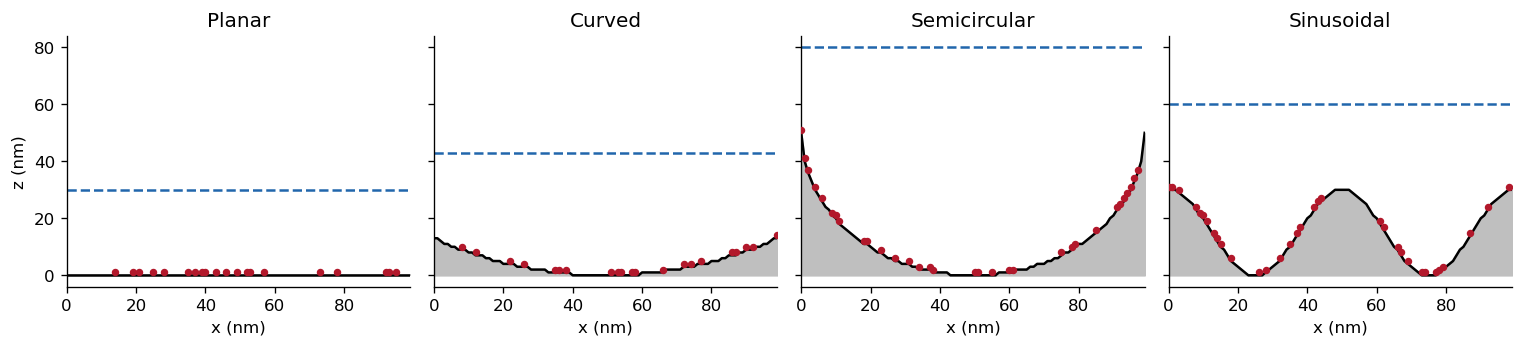

,geometry,receptors,maximum_height_nm,escape_height_nm
0,Planar,20,0.0,30.0
1,Curved,21,13.0,43.0
2,Semicircular,32,50.0,80.0
3,Sinusoidal,33,30.0,60.0


In [8]:
GEOMETRY_SPECS = [
    {'kind': 'planar', 'name': 'Planar'},
    {'kind': 'curved', 'name': 'Curved', 'radius_m': 100e-9},
    {'kind': 'semicircular', 'name': 'Semicircular'},
    {
        'kind': 'sinusoidal', 'name': 'Sinusoidal',
        'amplitude_m': 15e-9, 'wavelength_m': 50e-9,
    },
]

preview = {}
for index, specification in enumerate(GEOMETRY_SPECS):
    arguments = dict(specification)
    kind = arguments.pop('kind')
    name = arguments.pop('name')
    geometry = make_escape_geometry_2d(
        P, kind, name=name, seed=P.seed + index, **arguments
    )
    preview[name] = type('Preview', (), {'geometry': geometry, 'params': P})()

axes = plot_geometries_2d(preview)
plt.tight_layout()
plt.show()

pd.DataFrame([
    {
        'geometry': name,
        'receptors': item.geometry.n_receptors,
        'maximum_height_nm': item.geometry.height_m.max() * 1e9,
        'escape_height_nm': item.geometry.escape_z_m * 1e9,
    }
    for name, item in preview.items()
])

## Run the escape assays

Each receptor supplies an independent set of initially bound trajectories. Increase `n_trials_per_receptor` above after confirming the qualitative behavior.

In [62]:
results, trajectories = run_geometry_comparison_2d(
    P, geometry_specs=GEOMETRY_SPECS
)
summary = summarize_geometry_comparison_2d(trajectories)
summary

,geometry,n_trajectories,escape_probability,mean_observation_time_s,median_observation_time_s,mean_bound_time_s,mean_rebindings,mean_self_rebindings,mean_cross_rebindings
0,Planar,100,1.0,190.222035,145.775813,190.221991,0.950,0.950,0.00
1,Curved,100,1.0,223.851478,191.889255,223.851402,1.350,1.350,0.00
2,Semicircular,200,1.0,296.323959,197.732537,296.323766,1.645,1.595,0.05
3,Sinusoidal,200,1.0,274.485819,190.715927,274.485729,1.580,1.330,0.25


## Retention survival

A slower decline means that molecules remain associated with the local sensor region longer before reaching the bulk boundary. The dotted classical curve is $S(t)=\exp(-k_{off}t)$: a single initially bound interval followed by immediate loss, with no rebinding or post-dissociation retention.

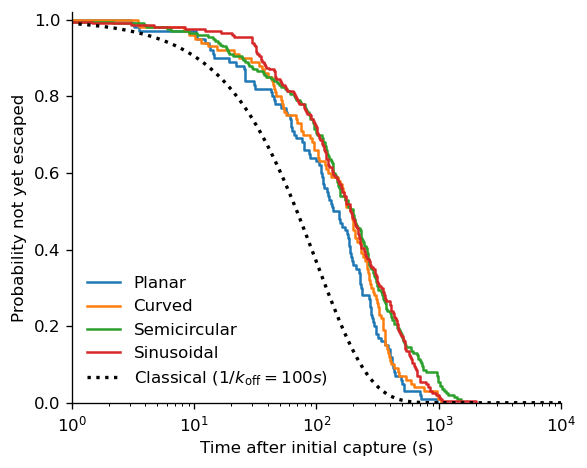

In [63]:
fig, ax = plt.subplots(figsize=(5.0, 4.0))
plot_survival_comparison_2d(results, ax=ax, include_classical=True)
ax.set_xscale('log')
ax.set_xlim(1, P.max_time_s)
plt.tight_layout()
plt.show()

## Residence-time distributions

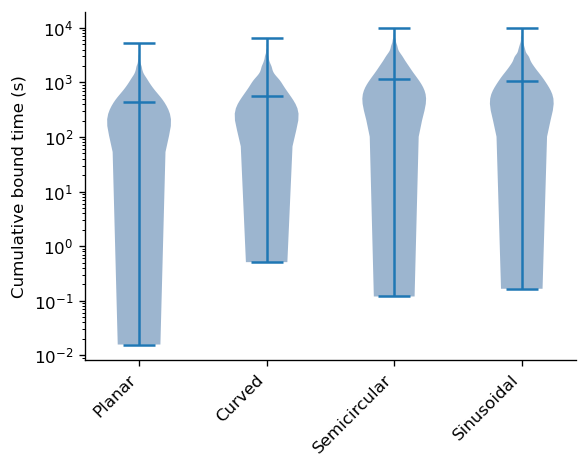

In [51]:
order = list(results)
fig, ax = plt.subplots(figsize=(5.0, 4.0))
values = [
    trajectories.loc[trajectories.geometry == name, 'total_bound_time_s']
    for name in order
]
parts = ax.violinplot(values, showmeans=False, showmedians=True)
for body in parts['bodies']:
    body.set_facecolor('#4C78A8')
    body.set_alpha(0.55)
ax.set(
    xticks=np.arange(1, len(order) + 1), xticklabels=order,
    ylabel='Cumulative bound time (s)', yscale='log'
)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Self- and cross-rebinding

These counts separate return to the receptor most recently vacated from transfer to another receptor.

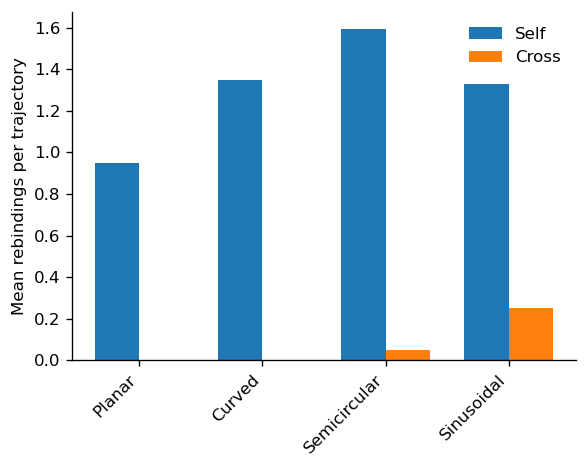

In [64]:
rebinding_summary = (
    trajectories.groupby('geometry', sort=False)
    [['n_self_rebindings', 'n_cross_rebindings']]
    .mean()
    .reindex(order)
)
fig, ax = plt.subplots(figsize=(5.0, 4.0))
x = np.arange(len(order))
width = 0.36
ax.bar(x - width/2, rebinding_summary.n_self_rebindings, width, label='Self')
ax.bar(x + width/2, rebinding_summary.n_cross_rebindings, width, label='Cross')
ax.set(
    xticks=x, xticklabels=order, ylabel='Mean rebindings per trajectory',
)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Interpretation and limitations

At fixed receptor line density, longer profiles contain more receptors. The comparison therefore intentionally combines confinement, curvature, surface length, and receptor number, much like a fixed surface-density experiment. A fixed-receptor-number control can separate shape from added receptor number. The model also places receptors in the fluid site immediately above the height graph; it does not resolve chemistry on vertical faces created by voxelization. The full 3D assay remains the quantitative model used for manuscript conclusions.